# Mini-Project 1: Weather Forecast with Python Web APIs

Data sources: Open-Meteo (geocoding and forecast) and MET Norway Locationforecast 2.0.

In [1]:
# --- CONFIGURATION: the only cell to edit ---
import os

LOCATION = "MUKONO"  # city to forecast; change if you like
COUNTRY_CODE = "UG"  # ISO country code to narrow the search; None = worldwide
LOCATION_CHOICE = 0  # number of the place to use, from the candidate list below
FORECAST_DAYS = 7    # number of days to forecast (1-16)

PLACEHOLDER_EMAIL = "YOUR_UNIVERSITY_EMAIL"
CONTACT_EMAIL = os.environ.get("WEATHER_CONTACT_EMAIL", PLACEHOLDER_EMAIL)
USER_AGENT = f"oop-python-assignment2/1.0 ({CONTACT_EMAIL})"

if CONTACT_EMAIL == PLACEHOLDER_EMAIL:
    print("WARNING: set WEATHER_CONTACT_EMAIL before calling the APIs.")
print("Location:", LOCATION)
print("Contact email configured:", CONTACT_EMAIL != PLACEHOLDER_EMAIL)

Location: MUKONO
Contact email configured: True


In [2]:
import json
import urllib.parse
import urllib.request

GEOCODING_URL = "https://geocoding-api.open-meteo.com/v1/search"

query = urllib.parse.urlencode(
    {"name": LOCATION, "count": 5, "language": "en", "format": "json"}
)
url = f"{GEOCODING_URL}?{query}"
req = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})

with urllib.request.urlopen(req, timeout=10) as resp:
    status_urllib = resp.status
    body = resp.read().decode("utf-8")

data_urllib = json.loads(body)
print("URL:", url)
print("Status:", status_urllib)
for place in data_urllib.get("results", []):
    print(place["name"], "|", place.get("admin1"), "|",
          place.get("country"), "|", place["latitude"], place["longitude"])

URL: https://geocoding-api.open-meteo.com/v1/search?name=MUKONO&count=5&language=en&format=json
Status: 200
Mukono | Central Region | Uganda | 0.35333 32.75528
Mukono | Northern Province | Rwanda | -1.4551 30.0149
Mokono | Kasai | Democratic Republic of Congo | -7.28013 21.62154
Mukono | Central Region | Uganda | 0.27276 32.46589
Mukono | Western Province | Zambia | -14.6 24.25


In [3]:
import requests

resp_requests = requests.get(
    GEOCODING_URL,
    params={"name": LOCATION, "count": 5, "language": "en", "format": "json"},
    headers={"User-Agent": USER_AGENT},
    timeout=10,
)
data_requests = resp_requests.json()

print("URL built by requests:", resp_requests.url)
print("Status:", resp_requests.status_code)
print("Number of results:", len(data_requests.get("results", [])))
print("Same results as urllib:",
      data_requests.get("results") == data_urllib.get("results"))

URL built by requests: https://geocoding-api.open-meteo.com/v1/search?name=MUKONO&count=5&language=en&format=json
Status: 200
Number of results: 5
Same results as urllib: True


##  urllib vs requests

| Aspect | urllib (standard library) | requests |
|---|---|---|
| Code length | 6 steps. urlencode, then Request, urlopen, read, decode and json.loads | 2 steps. requests.get(...) and .json() |
| Error handling | raises HTTPError automatically for 4xx and 5xx responses, and URLError for network failures. | does not raise for 4xx or 5xx, so you must call raise_for_status(). Network failures raise ConnectionError or Timeout, both under RequestException |
| Header control | you must build a Request object to add headers. | pass a headers= dictionary directly. | 
| Encoding | returns raw bytes. The code decoded them manually, assuming UTF-8. | reads charset=utf-8 from the Content-Type header and decodes automatically |

**Conclusion:**  Both methods gave the same results for Mukono. I'll use `requests` for the rest of the project because it's shorter and handles headers, parameters and encoding for me. The catch is that it doesn't flag 4xx/5xx errors on its own, so I'll need `raise_for_status()`. `urllib` is still handy when you can't install extra packages.

In [4]:
print("Status code:", resp_requests.status_code)
print("Content-Type:", resp_requests.headers.get("Content-Type"))
print("Response time (s):", round(resp_requests.elapsed.total_seconds(), 3))

Status code: 200
Content-Type: application/json; charset=utf-8
Response time (s): 0.766


## Part B: Forecast retrieval and display

In [5]:
%load_ext autoreload
%autoreload 2

import os
import sys

PROJECT_ROOT = os.path.abspath("..")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.weather import parse_geocoding_results

In [6]:
candidates = parse_geocoding_results(data_requests)
for number, place in enumerate(candidates):
    print(number, place)

print("No-results case:", parse_geocoding_results({}))


0 {'name': 'Mukono', 'admin1': 'Central Region', 'country': 'Uganda', 'latitude': 0.35333, 'longitude': 32.75528, 'timezone': 'Africa/Kampala', 'population': 191300}
1 {'name': 'Mukono', 'admin1': 'Northern Province', 'country': 'Rwanda', 'latitude': -1.4551, 'longitude': 30.0149, 'timezone': 'Africa/Kigali', 'population': None}
2 {'name': 'Mokono', 'admin1': 'Kasai', 'country': 'Democratic Republic of Congo', 'latitude': -7.28013, 'longitude': 21.62154, 'timezone': 'Africa/Lubumbashi', 'population': None}
3 {'name': 'Mukono', 'admin1': 'Central Region', 'country': 'Uganda', 'latitude': 0.27276, 'longitude': 32.46589, 'timezone': 'Africa/Kampala', 'population': None}
4 {'name': 'Mukono', 'admin1': 'Western Province', 'country': 'Zambia', 'latitude': -14.6, 'longitude': 24.25, 'timezone': 'Africa/Lusaka', 'population': None}
No-results case: []


In [7]:
from src.weather import geocode

candidates = geocode(LOCATION, USER_AGENT, country_code=COUNTRY_CODE)
for number, place in enumerate(candidates):
    print(number, place["name"], "|", place["admin1"], "|",
          place["country"], "| population:", place["population"])

0 Mukono | Central Region | Uganda | population: 191300
1 Mukono | Central Region | Uganda | population: None
2 Mukono Landing | Central Region | Uganda | population: None


In [8]:
from src.weather import choose_location

location = choose_location(candidates, LOCATION_CHOICE)
print(f"Using: {location['name']}, {location['admin1']}, {location['country']} "
      f"({location['latitude']}, {location['longitude']}), "
      f"timezone {location['timezone']}")

Using: Mukono, Central Region, Uganda (0.35333, 32.75528), timezone Africa/Kampala


In [9]:
from src.weather import get_forecast

forecast = get_forecast(location["latitude"], location["longitude"],
                        FORECAST_DAYS, USER_AGENT,
                        timezone=location["timezone"])
print("Timezone used:", forecast["timezone"])
print("Units:", forecast["daily_units"])
print("Dates:", forecast["daily"]["time"])

Timezone used: Africa/Kampala
Units: {'time': 'iso8601', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h', 'weather_code': 'wmo code'}
Dates: ['2026-10-12', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18']


In [10]:
from src.weather import forecast_to_dataframe

forecast_df = forecast_to_dataframe(forecast)
forecast_df

,Date,Weather,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind speed (km/h)
0,2026-10-12,Slight rain showers,25.4,18.8,3.5,14.8
1,2026-10-13,Moderate rain showers,25.2,19.3,5.0,9.7
2,2026-10-14,Moderate drizzle,27.6,18.3,0.7,10.1
3,2026-10-15,Slight or moderate thunderstorm,27.0,18.2,8.3,16.8
4,2026-10-16,Slight rain showers,24.4,18.2,14.5,12.4
5,2026-10-17,Light drizzle,24.1,19.4,1.5,10.4
6,2026-10-18,Slight rain showers,23.6,19.0,10.5,7.1


In [11]:
forecast_table = (
    forecast_df.style
    .format({"Date": "{:%a %d %b}"}, precision=1)
    .hide(axis="index")
    .set_caption(
        f"{FORECAST_DAYS}-day forecast for {location['name']}, "
        f"{location['country']}. Weather data by Open-Meteo.com"
    )
)
forecast_table

Date,Weather,Max temperature (°C),Min temperature (°C),Precipitation (mm),Max wind speed (km/h)
Mon 12 Oct,Slight rain showers,25.4,18.8,3.5,14.8
Tue 13 Oct,Moderate rain showers,25.2,19.3,5.0,9.7
Wed 14 Oct,Moderate drizzle,27.6,18.3,0.7,10.1
Thu 15 Oct,Slight or moderate thunderstorm,27.0,18.2,8.3,16.8
Fri 16 Oct,Slight rain showers,24.4,18.2,14.5,12.4
Sat 17 Oct,Light drizzle,24.1,19.4,1.5,10.4
Sun 18 Oct,Slight rain showers,23.6,19.0,10.5,7.1


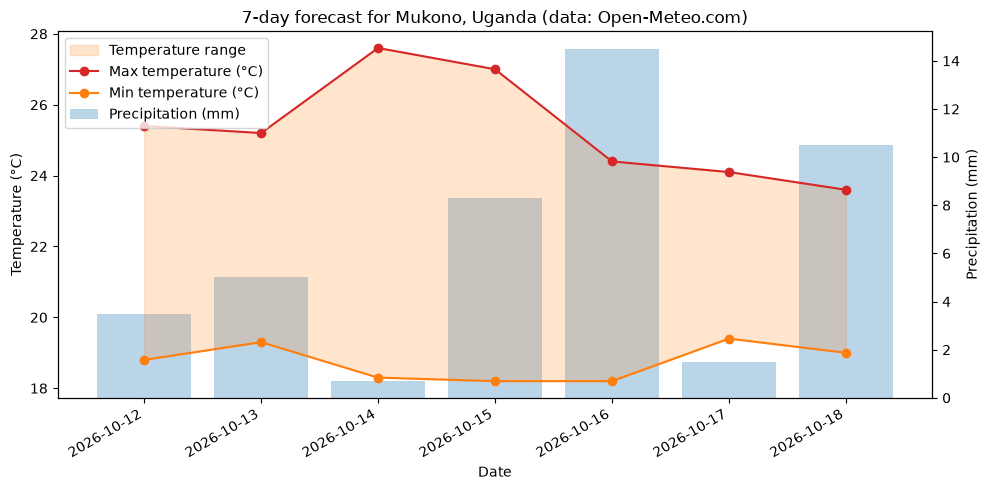

In [12]:
import matplotlib.pyplot as plt
from src.weather import plot_forecast

fig = plot_forecast(
    forecast_df,
    f"{FORECAST_DAYS}-day forecast for {location['name']}, "
    f"{location['country']} (data: Open-Meteo.com)",
)
plt.show()

In [13]:
from src.weather import summarise_forecast

print(summarise_forecast(forecast_df,
                         f"{location['name']}, {location['country']}"))

Forecast for Mukono, Uganda, Mon 12 Oct to Sun 18 Oct:
- Temperatures from 18.2 to 27.6 °C; warmest day Wed 14 Oct.
- Rain expected on 7 of 7 days, 44.0 mm in total; wettest day Fri 16 Oct (14.5 mm).
- Strongest wind 16.8 km/h on Thu 15 Oct.
- Most common conditions: Slight rain showers.
